In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)
keras.utils.set_random_seed(SEED)

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch

  plt.figure(figsize=(16,8))

  plt.subplot(1,2,1)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['loss'],label='Train Loss')
  plt.plot(hist['epoch'], hist['val_loss'], label = 'Val Loss')
  plt.legend()

  plt.subplot(1,2,2)
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.plot(hist['epoch'], hist['acc'], label='Train Accuracy')
  plt.plot(hist['epoch'], hist['val_acc'], label = 'Val Accuracy')

  plt.legend()
  plt.show()

In [6]:
(x_train,y_train),(x_test, y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [7]:
x_train.shape, y_train.shape

((50000, 32, 32, 3), (50000, 1))

In [8]:
x_test.shape, y_test.shape

((10000, 32, 32, 3), (10000, 1))

In [9]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2,shuffle=True,random_state=SEED)

In [10]:
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0

In [11]:
from keras.utils import to_categorical

y_train = y_train.reshape(-1)
y_val = y_val.reshape(-1)
y_test= y_test.reshape(-1)

y_train_e = to_categorical(y_train , num_classes = 10)
y_val_e = to_categorical(y_val , num_classes = 10)
y_test_e = to_categorical(y_test, num_classes = 10)

In [13]:
x_test.shape, y_test_e.shape

((10000, 32, 32, 3), (10000, 10))

In [14]:
from keras import layers

def build_model():
  model = keras.Sequential([
    keras.Input(shape=(32,32,3)),
    layers.Conv2D(filters=32,kernel_size=(3,3),activation = 'relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(filters=64,kernel_size=(3,3),activation = 'relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(filters=128,kernel_size=(3,3),activation = 'relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(256,activation = 'relu'),

    layers.Dense(32,activation = 'relu'),
    layers.Dense(10,activation = 'softmax')
  ])
  return model

In [15]:
model = build_model()

In [16]:
model.compile(
    loss = 'categorical_crossentropy',
    optimizer = 'adam',
    metrics =['acc']
)

In [17]:
es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode = "min",
    patience = 20
)

In [18]:
EPOCHS = 100
BATCH_SIZE = 64

history = model.fit(x_train, y_train_e,
          epochs=EPOCHS,
          validation_data=(x_val, y_val_e),
          callbacks=[es],
          batch_size= BATCH_SIZE,
          verbose= 1
)

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - acc: 0.3439 - loss: 1.8035 - val_acc: 0.3839 - val_loss: 1.8029
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.5380 - loss: 1.2860 - val_acc: 0.5836 - val_loss: 1.1764
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.6006 - loss: 1.1216 - val_acc: 0.6013 - val_loss: 1.1145
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.6416 - loss: 1.0100 - val_acc: 0.6125 - val_loss: 1.1518
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.6736 - loss: 0.9248 - val_acc: 0.6796 - val_loss: 0.9434
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.6968 - loss: 0.8595 - val_acc: 0.6225 - val_loss: 1.0903
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.7184 - loss: 0.8073 - val_acc: 0.7019 - val_loss: 0.8587
Epoch 8/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.7343 - loss: 0.7611 - val_acc: 0.6910 - val_loss: 0.9218
Epoch 9/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms

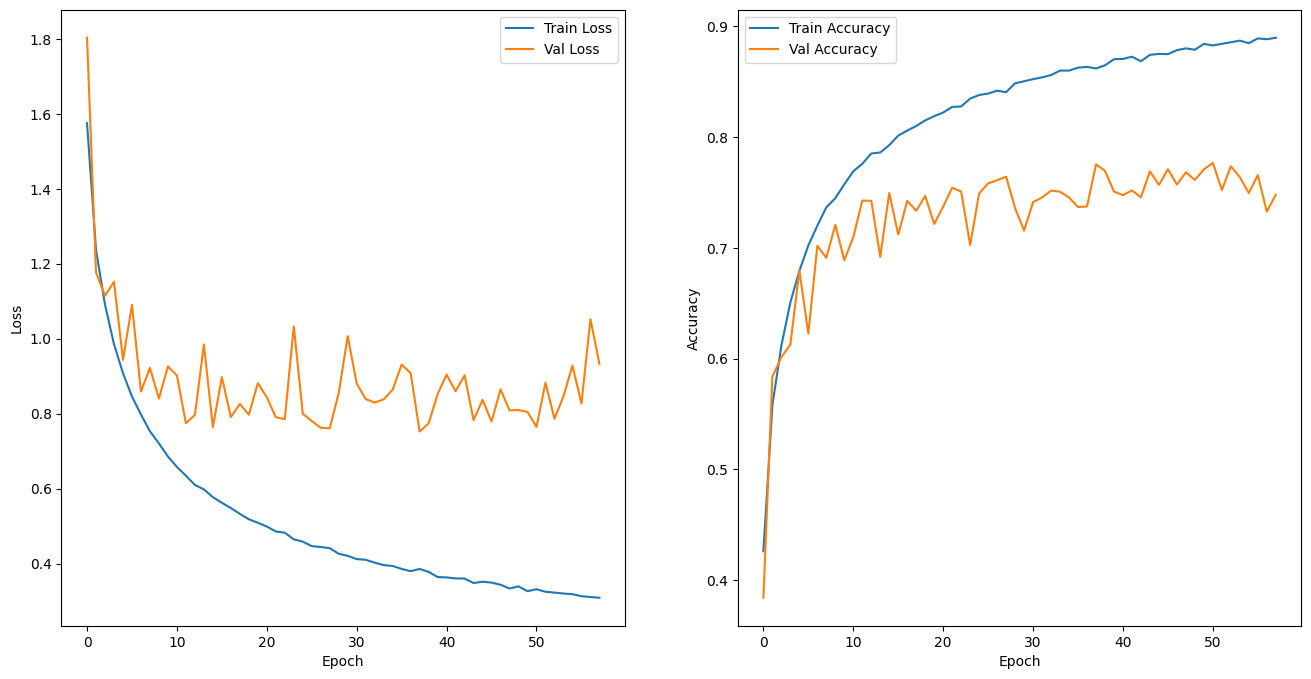

In [19]:
plot_history(history)

In [20]:
y_pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


In [21]:
y_pred.shape, y_test_e.shape

((10000, 10), (10000, 10))

정확도 0.7413
정밀도 0.7516
재현율 0.7413
f1 0.7387


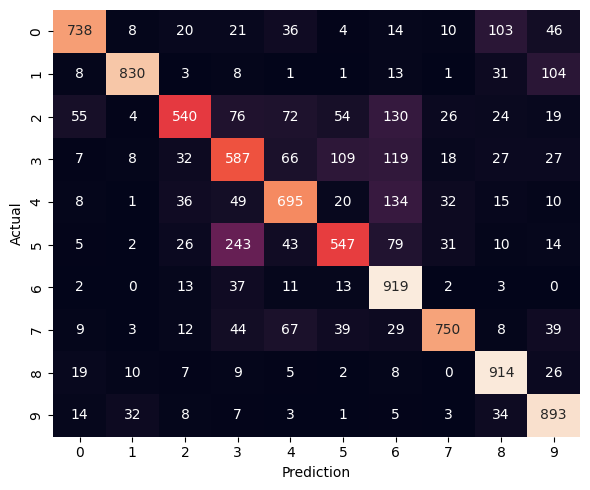

In [23]:
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score, confusion_matrix
import numpy as np # Add import for numpy

def print_metrics(y_true, y_pred):
    # Convert one-hot encoded y_true to class labels
    y_true_labels = np.argmax(y_true, axis=1)
    # Convert predicted probabilities to class labels
    y_pred_labels = np.argmax(y_pred, axis=1)

    acc = accuracy_score(y_true_labels, y_pred_labels)
    # Specify average for multiclass classification, 'macro' is a common choice.
    pre = precision_score(y_true_labels, y_pred_labels, average='macro')
    recall = recall_score(y_true_labels, y_pred_labels, average='macro')
    f1 = f1_score(y_true_labels, y_pred_labels, average='macro')

    print(f"정확도 {acc:.4f}")
    print(f"정밀도 {pre:.4f}")
    print(f"재현율 {recall:.4f}")
    print(f"f1 {f1:.4f}")

    cfm = confusion_matrix(y_true_labels,y_pred_labels)

    plt.figure(figsize=(6, 5)) # Optional: Adjust figure size for better visualization
    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.tight_layout() # Optional: Adjust layout to prevent labels from overlapping
    plt.show()

print_metrics(y_test_e, y_pred)